<a href="https://colab.research.google.com/github/pkucheryanov-cpu/IAD-TimeSeries-ARIMA/blob/main/ARIMA_forecast.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


0. ЗАВАНТАЖЕННЯ ДАНИХ
Файл dataset_time_series.csv завантажено.
Спостережень: 100; період: 2026-10-01 – 2027-01-08; пропусків: 0
Середнє = 72.32, стандартне відхилення = 5.15, min = 60.8, max = 82.8

КРОК 1. ДОСЛІДЖЕННЯ РЯДУ ТА ВИЗНАЧЕННЯ СТАЦІОНАРНОСТІ


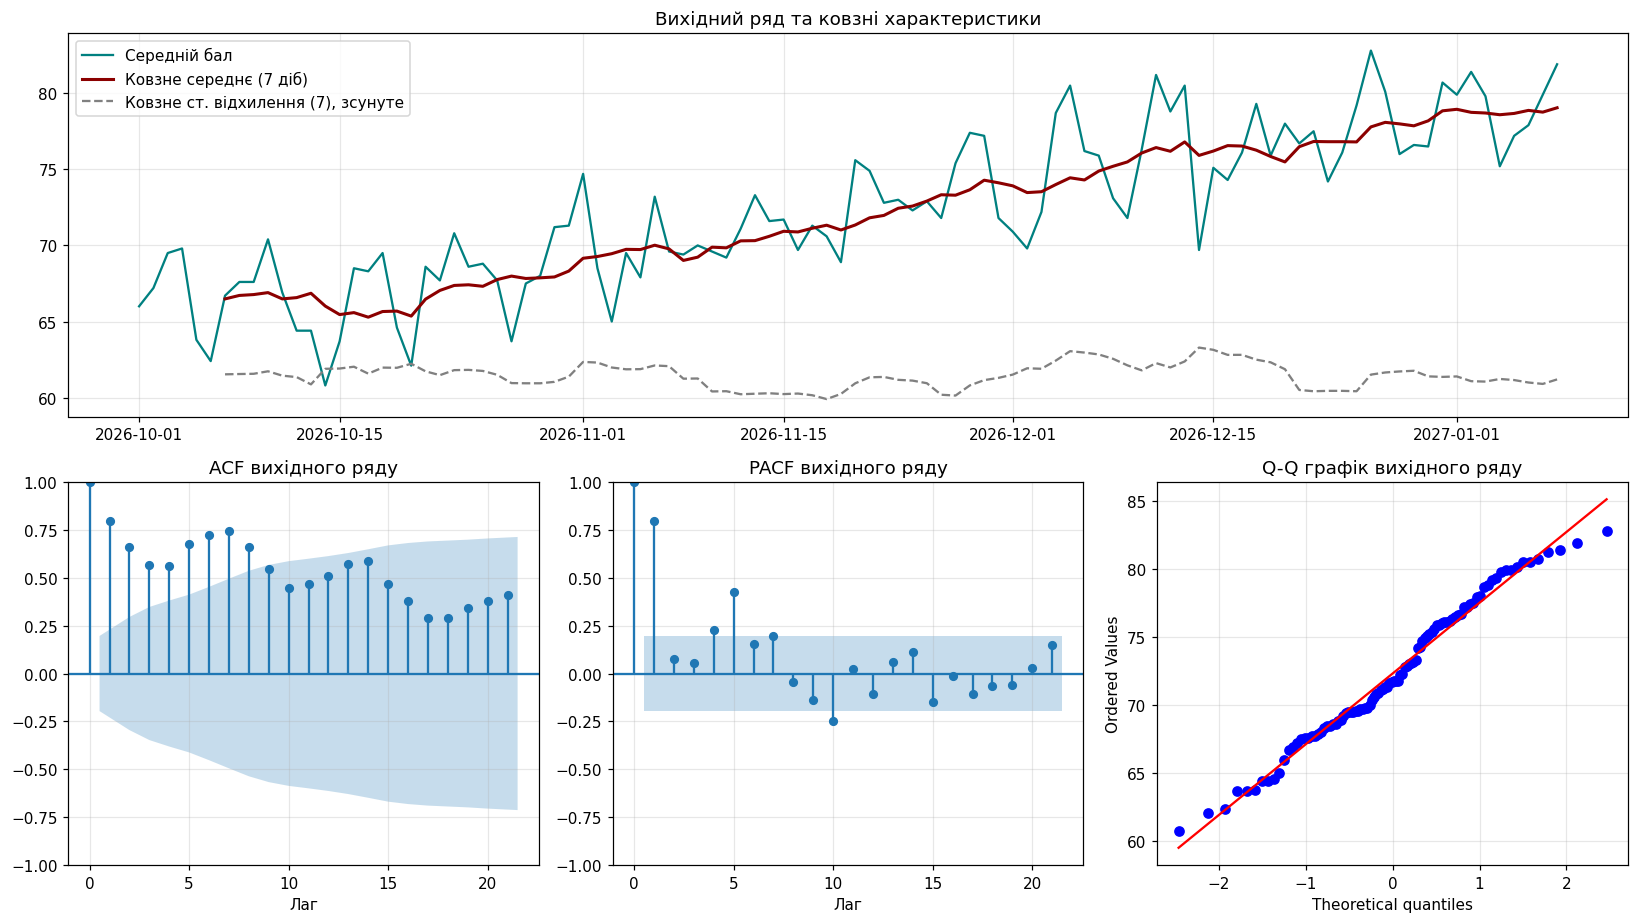

Перевірка стаціонарності вихідного ряду (рівень значущості 5%):
  ADF  (H0: ряд нестаціонарний):  статистика = -0.085, p = 0.9509  -> H0 не відхилено
  KPSS (H0: ряд стаціонарний):    статистика = 1.724, p = 0.0100  -> H0 відхилено

ACF: автокореляція повільно спадає (r1 = 0.80, r7 = 0.75, r14 = 0.59), значущих лагів: 21 з 21 (межа ±0.196).

Сталість дисперсії: кореляція Спірмена між середнім і ст. відхиленням тижневих блоків ρ = -0.03, p = 0.923 -> залежності немає: розмах коливань сталий, логарифмування не потрібне (адитивна структура).

ВИСНОВОК:
  Ряд НЕСТАЦІОНАРНИЙ: ADF не відхиляє гіпотезу про одиничний корінь, а KPSS відхиляє гіпотезу про стаціонарність; ACF спадає повільно та має сезонні піки на лагах, кратних 7. Причини нестаціонарності – зростаючий тренд (змінне середнє) і тижнева сезонність.

КРОК 2. ПРИВЕДЕННЯ РЯДУ ДО СТАЦІОНАРНОГО ВИГЛЯДУ
Порівняння варіантів диференціювання (d – регулярне, D – сезонне з лагом 7):
 d  D   N  Дисперсія  ADF p  KPSS p Стаціонарний
 0  0 100 

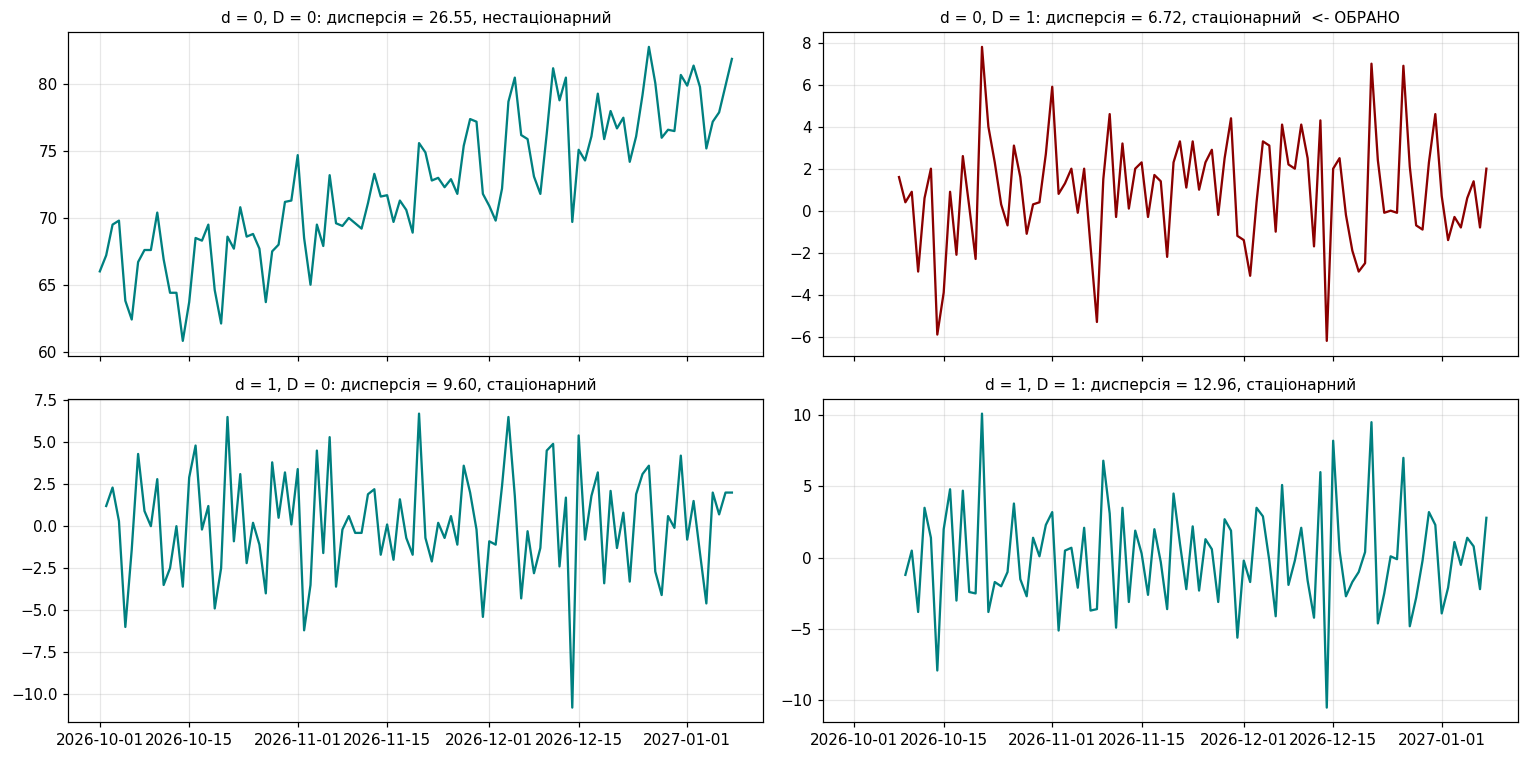


Перевірка перетвореного ряду:
  ADF:  p = 0.0000 (H0 про нестаціонарність відхилено)
  KPSS: p = 0.1000 (H0 про стаціонарність не відхилено)
ВИСНОВОК: ряд після диференціювання стаціонарний; тренд і сезонність усунуто.
Примітка: перетворений ряд має ненульове середнє (0.945) – це «дрейф» (постійна складова), тому в модель буде включено константу.

КРОК 3. ПІДБІР МОДЕЛІ ARIMA (ІДЕНТИФІКАЦІЯ)


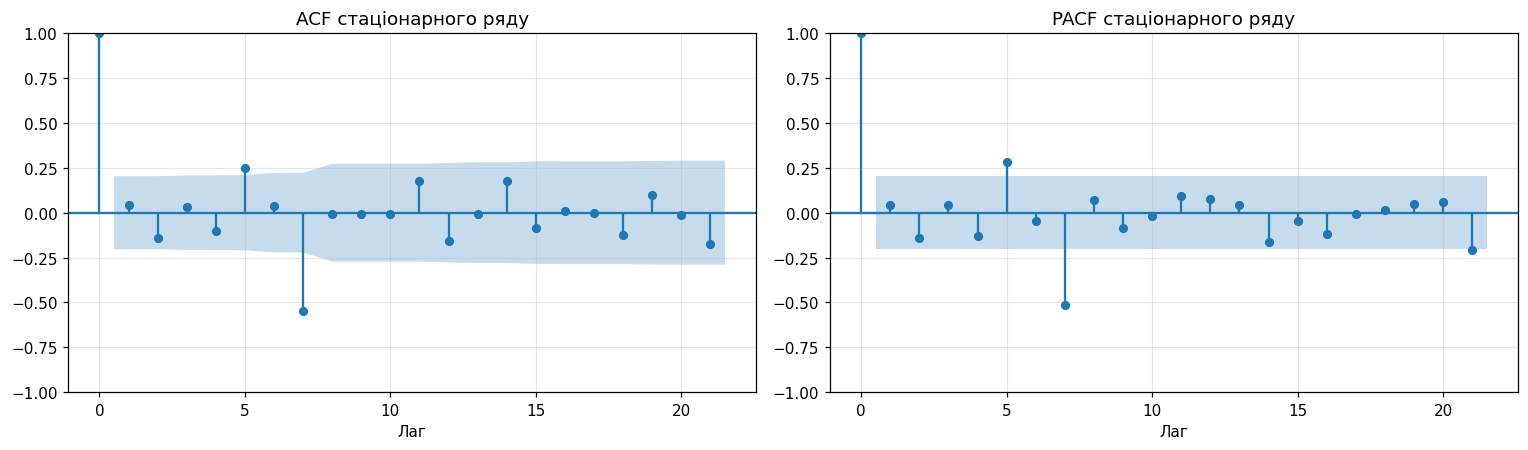

Межа значущості: ±0.203
Значущі лаги ACF:  [5, 7]
Значущі лаги PACF: [5, 7, 21]

Попередня ідентифікація за ACF/PACF:
  – значущий лаг 1 в ACF вказує на регулярну компоненту ковзного середнього (q = 1), у PACF – на авторегресію (p = 1);
  – значущий лаг 7 (і кратні) вказує на сезонну компоненту: в ACF – Q = 1, у PACF – P = 1;
  – якщо значущих лагів майже немає, ряд близький до білого шуму (p = q = 0).
Підказки з графіків для цього ряду: Q = 1, P = 1.

Пошук найкращої моделі за інформаційним критерієм Акайке (AIC) при d = 0, D = 1, сезонний лаг 7, константа: є:
                      Модель  k     AIC     BIC
0  ARIMA(1, 0, 2)x(0, 1, 1)7  6  344.99  359.50
1  ARIMA(0, 0, 2)x(0, 1, 1)7  5  345.09  357.19
2  ARIMA(2, 0, 2)x(0, 1, 1)7  7  346.43  363.37
3  ARIMA(0, 0, 2)x(1, 1, 1)7  6  347.09  361.60
4  ARIMA(0, 0, 1)x(0, 1, 1)7  4  352.08  361.80
5  ARIMA(1, 0, 1)x(0, 1, 1)7  5  352.96  365.11
6  ARIMA(0, 0, 0)x(0, 1, 1)7  3  353.09  360.42
7  ARIMA(2, 0, 1)x(0, 1, 1)7  6  354.33  368.91


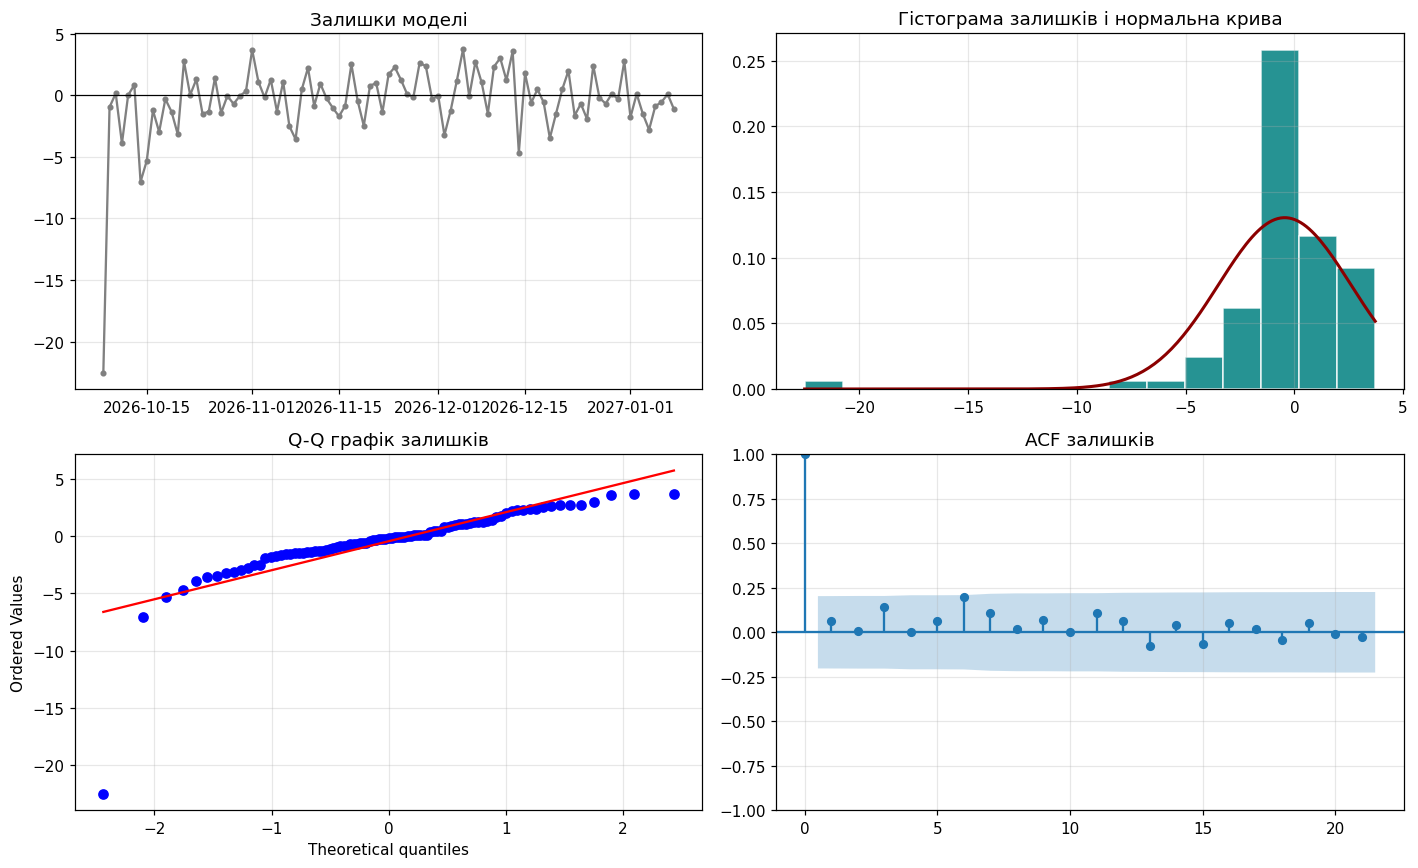


Автокореляція (ACF): лаги поза межами ±0.203: немає (при білому шумі очікується ≈ 1)

Тест Люнга–Бокса (H0: автокореляції залишків немає):
  лаг 10: Q = 8.520, p = 0.2024 -> H0 не відхилено
  лаг 20: Q = 12.505, p = 0.7085 -> H0 не відхилено

Інші властивості білого шуму:
  Середнє залишків = -0.4437; t-тест (H0: M = 0): p = 0.1649 -> нуль
  Нормальність: Шапіро–Вілка p = 0.0000; Харке–Бера p = 0.0000 -> відхилення від нормальності
  Однорідність дисперсії (Левен, перша/друга половини): p = 0.3716 -> дисперсія стала

ВИСНОВОК:
  Залишки не містять автокореляції (p Люнга–Бокса > 0,05), їхнє середнє статистично не відрізняється від нуля, але розподіл відхиляється від нормального (довірчі інтервали наближені). Залишки поводяться як білий шум, тому модель ВВАЖАЄТЬСЯ АДЕКВАТНОЮ.

КРОК 6. ПРОГНОЗ НА 10 ПЕРІОДІВ УПЕРЕД
              Дата  Прогноз  Нижня межа 95%  Верхня межа 95%  Ст. похибка
Крок h                                                                   
1       2027-01-09    82.87

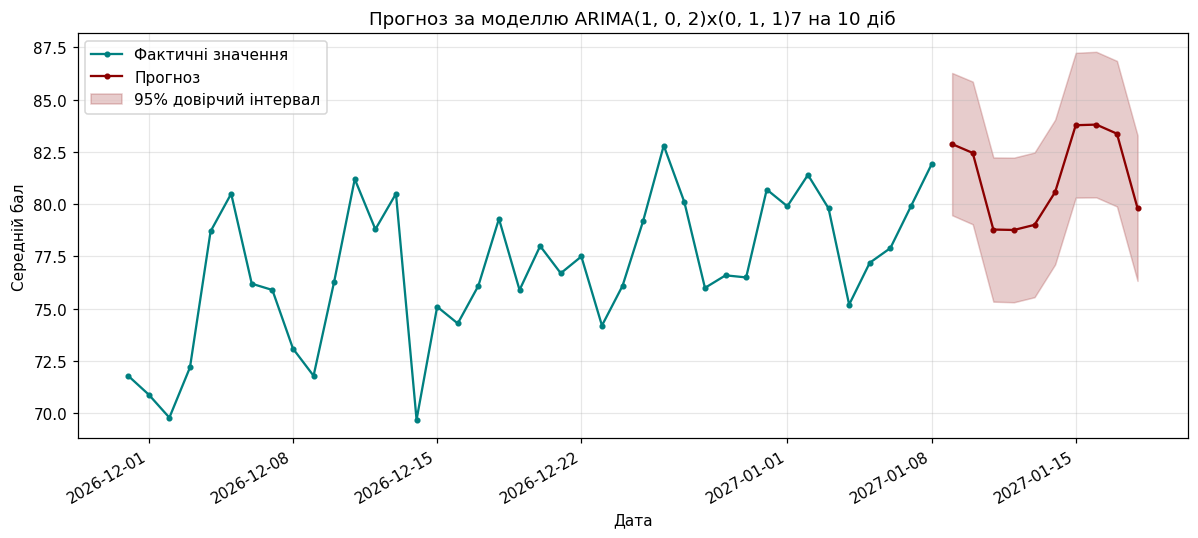


ВИСНОВОК: прогноз відтворює тренд і тижневу сезонність; значення на горизонті 10 діб змінюються від 78.8 до 83.8 бала. Довірчий інтервал розширюється зі зростанням горизонту (стандартна похибка збільшується в 1.02 раза), тобто далекі прогнози менш надійні.

--- Перевірка якості прогнозу: модель навчається на перших 90 спостереженнях, прогнозуються останні 10 ---
                                                 MAE  RMSE  MAPE, %  Покриття 95% ДІ, %  Сер. ширина ДІ
ARIMA(1, 0, 2)x(0, 1, 1)7                       1.33  1.60     1.69               100.0            6.97
Сезонний наївний прогноз                        2.09  2.56     2.63                 NaN             NaN
Регресія (тренд + дні тижня) з AR(1)-залишками  1.05  1.43     1.33               100.0            6.95


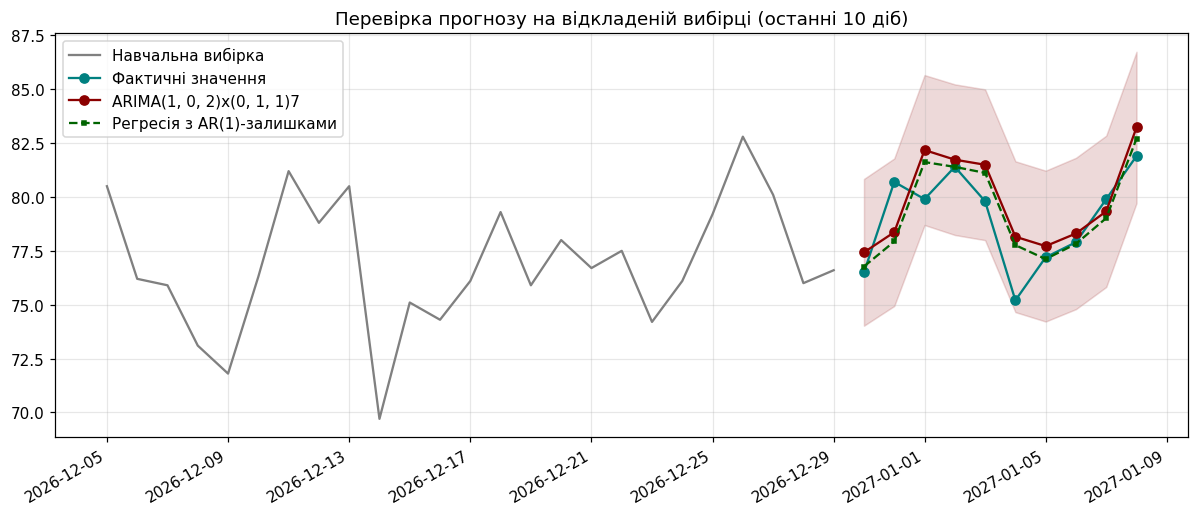


ВИСНОВОК: на відкладеній вибірці обраний ARIMA має RMSE = 1.60 бала (MAPE = 1.69%); найменшу похибку дала модель: Регресія (тренд + дні тижня) з AR(1)-залишками.
Примітка: детермінована структура ряду (лінійний тренд + тижнева сезонність) може описуватися регресією точніше, ніж диференціювання, яке збільшує дисперсію шуму; проте ARIMA залишається адекватною моделлю за критеріями залишків.


In [2]:
# -*- coding: utf-8 -*-
"""
Тема: прогнозування часового ряду моделями ARIMA (метод Бокса–Дженкінса)
Ряд: щоденний середній бал студентської групи (100 діб), файл dataset_time_series.csv

Порядок виконання роботи:
  1. Дослідження ряду та визначення стаціонарності (ADF, KPSS, ACF/PACF)
  2. Приведення ряду до стаціонарного вигляду (диференціювання)
  3. Підбір (ідентифікація) моделі ARIMA
  4. Знаходження параметрів моделі
  5. Перевірка адекватності моделі (аналіз залишків)
  6. Прогноз на 10 періодів уперед (+ перевірка якості прогнозу на відкладеній вибірці)

"""

import os
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

# ---------------------------------------------------------------------------
# НАЛАШТУВАННЯ
# ---------------------------------------------------------------------------
CSV_PATH = 'dataset_time_series.csv'
S = 7             # сезонний лаг (тижнева сезонність)
H = 10            # горизонт прогнозу (10 періодів)
ALPHA = 0.05      # рівень значущості
MAX_P, MAX_Q = 2, 2           # межі пошуку регулярних параметрів
MAX_SP, MAX_SQ = 1, 1         # межі пошуку сезонних параметрів
MAX_LAG = 21      # кількість лагів для ACF/PACF
RUN_ALTERNATIVE = True        # додатково порівняти з регресією з ARMA-залишками


def header(text):
    print("\n" + "=" * 80)
    print(text)
    print("=" * 80)


# ---------------------------------------------------------------------------
# 0. Дані
# ---------------------------------------------------------------------------
def generate_dataset():
    """Базовий код генерації ряду (використовується, якщо CSV не завантажено)."""
    np.random.seed(42)
    days = 100
    dates = pd.date_range(start='2026-10-01', periods=days, freq='D')
    trend = np.linspace(65, 80, days)
    seasonality = 3 * np.sin(2 * np.pi * np.arange(days) / 7)
    random_noise = np.random.normal(0, 2, days)
    average_score = np.clip(np.round(trend + seasonality + random_noise, 1), 0, 100)
    return pd.DataFrame({'Дата': dates, 'Період_t': range(1, days + 1),
                         'Середній_бал_Y': average_score})


def load_data():
    header("0. ЗАВАНТАЖЕННЯ ДАНИХ")
    if os.path.exists(CSV_PATH):
        df = pd.read_csv(CSV_PATH, parse_dates=['Дата'])
        print(f"Файл {CSV_PATH} завантажено.")
    else:
        df = generate_dataset()
        print(f"Файл {CSV_PATH} не знайдено – ряд згенеровано за базовим кодом.")
    y = pd.Series(df['Середній_бал_Y'].to_numpy(dtype=float),
                  index=pd.DatetimeIndex(df['Дата']), name='Середній бал').asfreq('D')
    print(f"Спостережень: {len(y)}; період: {y.index[0].date()} – {y.index[-1].date()}; "
          f"пропусків: {int(y.isna().sum())}")
    print(f"Середнє = {y.mean():.2f}, стандартне відхилення = {y.std():.2f}, "
          f"min = {y.min():.1f}, max = {y.max():.1f}")
    return y


# ---------------------------------------------------------------------------
# Допоміжні функції
# ---------------------------------------------------------------------------
def stationarity_tests(x):
    """ADF (H0: є одиничний корінь, ряд нестаціонарний) та KPSS (H0: ряд стаціонарний)."""
    x = pd.Series(x).dropna()
    adf = adfuller(x, autolag='AIC')
    kp = kpss(x, regression='c', nlags='auto')
    adf_ok = adf[1] < ALPHA            # H0 ADF відхилено -> свідчення на користь стаціонарності
    kpss_ok = kp[1] > ALPHA            # H0 KPSS не відхилено -> стаціонарність не спростовано
    if adf_ok and kpss_ok:
        verdict = 'стаціонарний'
    elif (not adf_ok) and (not kpss_ok):
        verdict = 'нестаціонарний'
    else:
        verdict = 'неоднозначно'
    return {'adf_stat': adf[0], 'adf_p': adf[1], 'kpss_stat': kp[0], 'kpss_p': kp[1],
            'stationary': adf_ok and kpss_ok, 'verdict': verdict}


def transform(y, d, D):
    """Регулярне (d) та сезонне (D, лаг S) диференціювання."""
    x = y.copy()
    for _ in range(D):
        x = x.diff(S)
    for _ in range(d):
        x = x.diff()
    return x.dropna()


def significant_lags(x, nlags=MAX_LAG):
    """Лаги ACF та PACF, що виходять за межі 95% довірчого інтервалу ±1.96/sqrt(n)."""
    x = pd.Series(x).dropna()
    bound = 1.96 / np.sqrt(len(x))
    a = acf(x, nlags=nlags, fft=False)
    p = pacf(x, nlags=nlags, method='ywm')
    sa = [k for k in range(1, nlags + 1) if abs(a[k]) > bound]
    sp = [k for k in range(1, nlags + 1) if abs(p[k]) > bound]
    return sa, sp, bound


def fit_sarima(y, order, seasonal_order, trend):
    model = SARIMAX(y, order=order, seasonal_order=seasonal_order, trend=trend,
                    enforce_stationarity=False, enforce_invertibility=False)
    return model.fit(disp=False, maxiter=300)


def label(order, seasonal_order):
    return f"ARIMA{order}x{seasonal_order[:3]}{seasonal_order[3]}"


# ---------------------------------------------------------------------------
# КРОК 1. Дослідження ряду, стаціонарність
# ---------------------------------------------------------------------------
def step1_explore(y):
    header("КРОК 1. ДОСЛІДЖЕННЯ РЯДУ ТА ВИЗНАЧЕННЯ СТАЦІОНАРНОСТІ")

    roll_m, roll_s = y.rolling(S).mean(), y.rolling(S).std()
    fig = plt.figure(figsize=(15, 8.5))
    ax = fig.add_subplot(2, 3, (1, 3))
    ax.plot(y, color='teal', label='Середній бал')
    ax.plot(roll_m, color='darkred', linewidth=2, label=f'Ковзне середнє ({S} діб)')
    ax.plot(roll_s + y.min() - 2, color='gray', linestyle='--', label=f'Ковзне ст. відхилення ({S}), зсунуте')
    ax.set_title('Вихідний ряд та ковзні характеристики'); ax.legend()
    plot_acf(y, lags=MAX_LAG, ax=fig.add_subplot(2, 3, 4), alpha=ALPHA)
    plot_pacf(y, lags=MAX_LAG, ax=fig.add_subplot(2, 3, 5), alpha=ALPHA, method='ywm')
    ax = fig.add_subplot(2, 3, 6)
    stats.probplot(y.dropna(), dist='norm', plot=ax)
    ax.set_title('Q-Q графік вихідного ряду')
    for a in fig.axes[1:3]:
        a.set_xlabel('Лаг')
    fig.axes[1].set_title('ACF вихідного ряду'); fig.axes[2].set_title('PACF вихідного ряду')
    plt.tight_layout(); plt.savefig('fig1_series_acf_pacf.png', dpi=150); plt.show()

    # --- Тести стаціонарності ---
    t = stationarity_tests(y)
    print("Перевірка стаціонарності вихідного ряду (рівень значущості 5%):")
    print(f"  ADF  (H0: ряд нестаціонарний):  статистика = {t['adf_stat']:.3f}, p = {t['adf_p']:.4f}  "
          f"-> {'H0 відхилено' if t['adf_p'] < ALPHA else 'H0 не відхилено'}")
    print(f"  KPSS (H0: ряд стаціонарний):    статистика = {t['kpss_stat']:.3f}, p = {t['kpss_p']:.4f}  "
          f"-> {'H0 відхилено' if t['kpss_p'] < ALPHA else 'H0 не відхилено'}")

    sa, sp, bound = significant_lags(y)
    a = acf(y, nlags=MAX_LAG, fft=False)
    print(f"\nACF: автокореляція повільно спадає (r1 = {a[1]:.2f}, r7 = {a[7]:.2f}, r14 = {a[14]:.2f}), "
          f"значущих лагів: {len(sa)} з {MAX_LAG} (межа ±{bound:.3f}).")

    # --- Перевірка сталості дисперсії (потреба логарифмування) ---
    n_blocks = len(y) // S
    blocks = y.values[: n_blocks * S].reshape(n_blocks, S)
    rho, p_rho = stats.spearmanr(blocks.mean(axis=1), blocks.std(axis=1, ddof=1))
    need_log = (p_rho < ALPHA) and (rho > 0)
    print(f"\nСталість дисперсії: кореляція Спірмена між середнім і ст. відхиленням тижневих блоків "
          f"ρ = {rho:.2f}, p = {p_rho:.3f} -> "
          f"{'розмах коливань зростає з рівнем ряду: потрібне логарифмування' if need_log else 'залежності немає: розмах коливань сталий, логарифмування не потрібне (адитивна структура)'}.")

    print("\nВИСНОВОК:")
    print(f"  Ряд {t['verdict'].upper()}: " + (
        "ADF не відхиляє гіпотезу про одиничний корінь, а KPSS відхиляє гіпотезу про стаціонарність; "
        "ACF спадає повільно та має сезонні піки на лагах, кратних 7. "
        "Причини нестаціонарності – зростаючий тренд (змінне середнє) і тижнева сезонність."
        if t['verdict'] == 'нестаціонарний' else
        "результати тестів потребують додаткового аналізу (див. значення статистик)."))
    return need_log


# ---------------------------------------------------------------------------
# КРОК 2. Приведення до стаціонарного вигляду
# ---------------------------------------------------------------------------
def step2_make_stationary(y):
    header("КРОК 2. ПРИВЕДЕННЯ РЯДУ ДО СТАЦІОНАРНОГО ВИГЛЯДУ")
    rows, series = [], {}
    for d, D in itertools.product((0, 1), (0, 1)):
        x = transform(y, d, D) if (d or D) else y.copy()
        t = stationarity_tests(x)
        rows.append({'d': d, 'D': D, 'N': len(x), 'Дисперсія': x.var(), 'ADF p': t['adf_p'],
                     'KPSS p': t['kpss_p'], 'Стаціонарний': 'так' if t['stationary'] else 'ні'})
        series[(d, D)] = (x, t['stationary'])
    tab = pd.DataFrame(rows)
    print("Порівняння варіантів диференціювання (d – регулярне, D – сезонне з лагом 7):")
    print(tab.round(4).to_string(index=False))

    stat = [(k, v[0].var()) for k, v in series.items() if v[1]]
    if stat:
        (d, D), var = min(stat, key=lambda z: z[1])
        print(f"\nКритерій вибору: серед стаціонарних варіантів обирається той, що має найменшу "
              f"дисперсію (зайве диференціювання її збільшує).")
    else:
        d, D = 1, 1
        print("\nЖоден варіант не пройшов обидва тести – обрано d = 1, D = 1.")
    w = series[(d, D)][0]
    print(f"ОБРАНО: d = {d}, D = {D}; дисперсія перетвореного ряду = {w.var():.3f}; "
          f"середнє = {w.mean():.3f}.")

    fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
    for ax, ((dd, DD), (x, ok)) in zip(axes.ravel(), series.items()):
        ax.plot(x, color='teal' if (dd, DD) != (d, D) else 'darkred')
        ax.set_title(f"d = {dd}, D = {DD}: дисперсія = {x.var():.2f}, "
                     f"{'стаціонарний' if ok else 'нестаціонарний'}"
                     f"{'  <- ОБРАНО' if (dd, DD) == (d, D) else ''}", fontsize=10)
    plt.tight_layout(); plt.savefig('fig2_differencing.png', dpi=150); plt.show()

    t = stationarity_tests(w)
    print("\nПеревірка перетвореного ряду:")
    print(f"  ADF:  p = {t['adf_p']:.4f} (H0 про нестаціонарність {'відхилено' if t['adf_p'] < ALPHA else 'не відхилено'})")
    print(f"  KPSS: p = {t['kpss_p']:.4f} (H0 про стаціонарність {'не відхилено' if t['kpss_p'] > ALPHA else 'відхилено'})")
    print(f"ВИСНОВОК: ряд після диференціювання {t['verdict']}; тренд і сезонність усунуто.")
    if d + D == 1:
        print(f"Примітка: перетворений ряд має ненульове середнє ({w.mean():.3f}) – "
              "це «дрейф» (постійна складова), тому в модель буде включено константу.")
    return d, D, w


# ---------------------------------------------------------------------------
# КРОК 3. Підбір (ідентифікація) моделі
# ---------------------------------------------------------------------------
def step3_identify(y, d, D, w):
    header("КРОК 3. ПІДБІР МОДЕЛІ ARIMA (ІДЕНТИФІКАЦІЯ)")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    plot_acf(w, lags=MAX_LAG, ax=axes[0], alpha=ALPHA)
    plot_pacf(w, lags=MAX_LAG, ax=axes[1], alpha=ALPHA, method='ywm')
    axes[0].set_title('ACF стаціонарного ряду'); axes[1].set_title('PACF стаціонарного ряду')
    for ax in axes:
        ax.set_xlabel('Лаг')
    plt.tight_layout(); plt.savefig('fig3_acf_pacf_stationary.png', dpi=150); plt.show()

    sa, sp, bound = significant_lags(w)
    print(f"Межа значущості: ±{bound:.3f}")
    print(f"Значущі лаги ACF:  {sa if sa else 'немає'}")
    print(f"Значущі лаги PACF: {sp if sp else 'немає'}")
    print("\nПопередня ідентифікація за ACF/PACF:")
    print("  – значущий лаг 1 в ACF вказує на регулярну компоненту ковзного середнього (q = 1), "
          "у PACF – на авторегресію (p = 1);")
    print(f"  – значущий лаг {S} (і кратні) вказує на сезонну компоненту: в ACF – Q = 1, у PACF – P = 1;")
    print("  – якщо значущих лагів майже немає, ряд близький до білого шуму (p = q = 0).")
    hints = []
    if 1 in sa: hints.append('q = 1')
    if 1 in sp: hints.append('p = 1')
    if S in sa: hints.append('Q = 1')
    if S in sp: hints.append('P = 1')
    print(f"Підказки з графіків для цього ряду: {', '.join(hints) if hints else 'сезонних/регулярних лагів немає'}.")

    trend = 'c' if (d + D) <= 1 else 'n'
    print(f"\nПошук найкращої моделі за інформаційним критерієм Акайке (AIC) при d = {d}, D = {D}, "
          f"сезонний лаг {S}, константа: {'є' if trend == 'c' else 'немає'}:")
    rows = []
    for p, q, P, Q in itertools.product(range(MAX_P + 1), range(MAX_Q + 1),
                                        range(MAX_SP + 1), range(MAX_SQ + 1)):
        try:
            res = fit_sarima(y, (p, d, q), (P, D, Q, S), trend)
            rows.append({'Модель': label((p, d, q), (P, D, Q, S)), 'p': p, 'q': q, 'P': P, 'Q': Q,
                         'k': len(res.params), 'AIC': res.aic, 'BIC': res.bic})
        except Exception:
            continue
    ranking = pd.DataFrame(rows).sort_values('AIC').reset_index(drop=True)
    print(ranking.head(8)[['Модель', 'k', 'AIC', 'BIC']].round(2).to_string())
    best = ranking.iloc[0]
    best_bic = ranking.sort_values('BIC').iloc[0]
    order = (int(best['p']), d, int(best['q']))
    seasonal = (int(best['P']), D, int(best['Q']), S)
    print(f"\nОБРАНА МОДЕЛЬ (мінімум AIC = {best['AIC']:.2f}): {label(order, seasonal)}")
    if best_bic['Модель'] != best['Модель']:
        print(f"Примітка: за критерієм BIC (сильніше штрафує складність) кращою є {best_bic['Модель']}.")
    return order, seasonal, trend, ranking


# ---------------------------------------------------------------------------
# КРОК 4. Параметри моделі
# ---------------------------------------------------------------------------
def model_equation(order, seasonal, trend, params):
    """Записує рівняння моделі: ліва частина – оператори, права – константа та ковзне середнє."""
    p, d, q = order
    P, D, Q, s = seasonal

    def poly(prefix, n, step, sign):
        terms = ''
        for i in range(1, n + 1):
            key = f"{prefix}.L{i * step}" if step == 1 else f"{prefix}.S.L{i * step}"
            c = params.get(key, 0.0)
            terms += f" {'−' if sign * c < 0 else '+'} {abs(c):.3f}·B{'' if i * step == 1 else '^' + str(i * step)}"
        return terms

    left = ''
    if p: left += f"(1{poly('ar', p, 1, -1)})"
    if P: left += f"(1{poly('ar', P, s, -1)})"
    if d: left += f"(1 − B)^{d}"
    if D: left += f"(1 − B^{s})^{D}"
    left = (left or '') + 'Yₜ'
    right = ''
    if trend == 'c': right += f"{params.get('intercept', 0.0):.3f} + "
    right += ('(1' + poly('ma', q, 1, 1) + ')') if q else ''
    right += ('(1' + poly('ma', Q, s, 1) + ')') if Q else ''
    right += 'εₜ'
    return f"{left} = {right}"


def step4_fit(y, order, seasonal, trend):
    header(f"КРОК 4. ПАРАМЕТРИ МОДЕЛІ {label(order, seasonal)}")
    res = fit_sarima(y, order, seasonal, trend)
    ci = res.conf_int()
    tab = pd.DataFrame({'Оцінка': res.params, 'Ст.помилка': res.bse, 'z': res.zvalues,
                        'p-значення': res.pvalues, '95% ДІ від': ci.iloc[:, 0], '95% ДІ до': ci.iloc[:, 1]})
    tab['Значущий (p < 0,05)'] = np.where(tab['p-значення'] < ALPHA, 'так', 'ні')
    print("Оцінки параметрів (метод максимальної правдоподібності):")
    print(tab.round(4).to_string())
    print(f"\nlogL = {res.llf:.2f}; AIC = {res.aic:.2f}; BIC = {res.bic:.2f}")
    print("\nГіпотези для кожного параметра: H0: параметр = 0; H1: параметр ≠ 0.")
    insig = [n for n in tab.index if n != 'sigma2' and tab.loc[n, 'p-значення'] >= ALPHA]
    print("ВИСНОВОК: " + ("усі параметри статистично значущі." if not insig else
                          f"незначущі параметри: {', '.join(insig)} "
                          "(їх можна виключити, якщо це не погіршує адекватність)."))
    print("\nРівняння моделі (B – оператор зсуву назад, εₜ – білий шум):")
    print("  " + model_equation(order, seasonal, trend, res.params.to_dict()))
    print(f"  дисперсія залишків σ² = {res.params.get('sigma2', np.nan):.3f}")
    print("\nПовний звіт statsmodels:")
    print(res.summary())
    return res


# ---------------------------------------------------------------------------
# КРОК 5. Адекватність моделі
# ---------------------------------------------------------------------------
def step5_adequacy(res, order, seasonal):
    header("КРОК 5. ПЕРЕВІРКА АДЕКВАТНОСТІ МОДЕЛІ (АНАЛІЗ ЗАЛИШКІВ)")
    burn = order[1] + seasonal[1] * S               # перші спостереження «поглинає» диференціювання
    resid = pd.Series(res.resid).iloc[burn:]
    n = len(resid)
    k = order[0] + order[2] + seasonal[0] + seasonal[2]
    print(f"Залишків для аналізу: {n} (перші {burn} відкинуто через диференціювання).")

    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    axes[0, 0].plot(resid, color='gray', marker='o', markersize=3)
    axes[0, 0].axhline(0, color='black', linewidth=0.8); axes[0, 0].set_title('Залишки моделі')
    axes[0, 1].hist(resid, bins=15, density=True, color='teal', edgecolor='white', alpha=0.85)
    xs = np.linspace(resid.min(), resid.max(), 200)
    axes[0, 1].plot(xs, stats.norm.pdf(xs, resid.mean(), resid.std()), color='darkred', linewidth=2)
    axes[0, 1].set_title('Гістограма залишків і нормальна крива')
    stats.probplot(resid, dist='norm', plot=axes[1, 0]); axes[1, 0].set_title('Q-Q графік залишків')
    plot_acf(resid, lags=MAX_LAG, ax=axes[1, 1], alpha=ALPHA); axes[1, 1].set_title('ACF залишків')
    plt.tight_layout(); plt.savefig('fig4_residual_diagnostics.png', dpi=150); plt.show()

    a = acf(resid, nlags=MAX_LAG, fft=False)
    bound = 1.96 / np.sqrt(n)
    outside = [i for i in range(1, MAX_LAG + 1) if abs(a[i]) > bound]
    lb = acorr_ljungbox(resid, lags=[10, 20], model_df=k, return_df=True)
    sh_stat, sh_p = stats.shapiro(resid)
    jb_stat, jb_p = stats.jarque_bera(resid)
    t_stat, t_p = stats.ttest_1samp(resid, 0.0)
    half = n // 2
    lev_stat, lev_p = stats.levene(resid.iloc[:half], resid.iloc[half:])

    print(f"\nАвтокореляція (ACF): лаги поза межами ±{bound:.3f}: {outside if outside else 'немає'} "
          f"(при білому шумі очікується ≈ {ALPHA * MAX_LAG:.0f})")
    print("\nТест Люнга–Бокса (H0: автокореляції залишків немає):")
    for lag, row in lb.iterrows():
        print(f"  лаг {lag:>2}: Q = {row['lb_stat']:.3f}, p = {row['lb_pvalue']:.4f} "
              f"-> {'H0 не відхилено' if row['lb_pvalue'] > ALPHA else 'H0 відхилено'}")
    print("\nІнші властивості білого шуму:")
    print(f"  Середнє залишків = {resid.mean():+.4f}; t-тест (H0: M = 0): p = {t_p:.4f} "
          f"-> {'нуль' if t_p > ALPHA else 'відмінне від нуля'}")
    print(f"  Нормальність: Шапіро–Вілка p = {sh_p:.4f}; Харке–Бера p = {jb_p:.4f} "
          f"-> {'нормальний розподіл не спростовано' if min(sh_p, jb_p) > ALPHA else 'відхилення від нормальності'}")
    print(f"  Однорідність дисперсії (Левен, перша/друга половини): p = {lev_p:.4f} "
          f"-> {'дисперсія стала' if lev_p > ALPHA else 'дисперсія змінюється'}")

    no_autocorr = bool((lb['lb_pvalue'] > ALPHA).all())
    adequate = no_autocorr and t_p > ALPHA
    print("\nВИСНОВОК:")
    if adequate:
        print("  Залишки не містять автокореляції (p Люнга–Бокса > 0,05), їхнє середнє статистично не "
              "відрізняється від нуля" + (", розподіл близький до нормального" if min(sh_p, jb_p) > ALPHA
                                          else ", але розподіл відхиляється від нормального (довірчі інтервали наближені)") +
              ". Залишки поводяться як білий шум, тому модель ВВАЖАЄТЬСЯ АДЕКВАТНОЮ.")
    else:
        print("  У залишках є автокореляція або систематичне зміщення: модель НЕ є адекватною. "
              "Слід змінити порядок моделі (збільшити p, q, P, Q) або перевірити диференціювання.")
    return adequate


# ---------------------------------------------------------------------------
# КРОК 6. Прогноз
# ---------------------------------------------------------------------------
def metrics(actual, forecast, lower=None, upper=None):
    err = actual - forecast
    out = {'MAE': np.abs(err).mean(), 'RMSE': np.sqrt((err ** 2).mean()),
           'MAPE, %': (np.abs(err) / actual).mean() * 100}
    if lower is not None:
        out['Покриття 95% ДІ, %'] = ((actual >= lower) & (actual <= upper)).mean() * 100
        out['Сер. ширина ДІ'] = (upper - lower).mean()
    return out


def design_matrix(t):
    X = pd.DataFrame({'t': t.astype(float)})
    for k in range(1, S):
        X[f'день{k}'] = (t % S == k).astype(float)
    return X


def step6_forecast(y, res, order, seasonal, trend, adequate):
    header(f"КРОК 6. ПРОГНОЗ НА {H} ПЕРІОДІВ УПЕРЕД")
    if not adequate:
        print("УВАГА: модель не визнано адекватною – прогноз орієнтовний.\n")

    fc = res.get_forecast(steps=H).summary_frame(alpha=ALPHA)
    table = pd.DataFrame({'Дата': fc.index.date, 'Прогноз': fc['mean'].to_numpy(),
                          'Нижня межа 95%': fc['mean_ci_lower'].to_numpy(),
                          'Верхня межа 95%': fc['mean_ci_upper'].to_numpy(),
                          'Ст. похибка': fc['mean_se'].to_numpy()})
    table.index = range(1, H + 1)
    table.index.name = 'Крок h'
    print(table.round(2).to_string())
    table.to_csv('arima_forecast_10.csv', index=True, encoding='utf-8-sig')
    print("\nПрогноз збережено у файл arima_forecast_10.csv")

    fig, ax = plt.subplots(figsize=(11, 5))
    tail = y.iloc[-40:]
    ax.plot(tail.index, tail, color='teal', marker='o', markersize=3, label='Фактичні значення')
    ax.plot(fc.index, fc['mean'], color='darkred', marker='o', markersize=3, label='Прогноз')
    ax.fill_between(fc.index, fc['mean_ci_lower'], fc['mean_ci_upper'], color='darkred', alpha=0.2, label='95% довірчий інтервал')
    ax.set_title(f'Прогноз за моделлю {label(order, seasonal)} на {H} діб')
    ax.set_xlabel('Дата'); ax.set_ylabel('Середній бал'); ax.legend(); fig.autofmt_xdate()
    plt.tight_layout(); plt.savefig('fig5_forecast.png', dpi=150); plt.show()

    widen = table['Ст. похибка'].iloc[-1] / table['Ст. похибка'].iloc[0]
    print(f"\nВИСНОВОК: прогноз відтворює тренд і тижневу сезонність; значення на горизонті "
          f"{H} діб змінюються від {table['Прогноз'].min():.1f} до {table['Прогноз'].max():.1f} бала. "
          f"Довірчий інтервал розширюється зі зростанням горизонту (стандартна похибка збільшується "
          f"в {widen:.2f} раза), тобто далекі прогнози менш надійні.")

    # ---- Перевірка якості прогнозу на відкладеній вибірці ----
    print("\n--- Перевірка якості прогнозу: модель навчається на перших "
          f"{len(y) - H} спостереженнях, прогнозуються останні {H} ---")
    train, test = y.iloc[:-H], y.iloc[-H:]
    res_tr = fit_sarima(train, order, seasonal, trend)
    f_tr = res_tr.get_forecast(steps=H).summary_frame(alpha=ALPHA)
    rows = {label(order, seasonal): metrics(test.values, f_tr['mean'].to_numpy(),
                                             f_tr['mean_ci_lower'].to_numpy(), f_tr['mean_ci_upper'].to_numpy())}
    snaive = np.array([train.iloc[-S + (h % S)] for h in range(H)])
    rows['Сезонний наївний прогноз'] = metrics(test.values, snaive)

    f_alt = None
    if RUN_ALTERNATIVE:
        t_all = np.arange(len(y))
        Xtr = design_matrix(t_all[:-H]); Xtr.index = train.index
        Xte = design_matrix(t_all[-H:]); Xte.index = test.index
        res_alt = SARIMAX(train, exog=Xtr, order=(1, 0, 0), trend='c').fit(disp=False, maxiter=300)
        f_alt = res_alt.get_forecast(steps=H, exog=Xte).summary_frame(alpha=ALPHA)
        rows['Регресія (тренд + дні тижня) з AR(1)-залишками'] = metrics(
            test.values, f_alt['mean'].to_numpy(), f_alt['mean_ci_lower'].to_numpy(), f_alt['mean_ci_upper'].to_numpy())
    comp = pd.DataFrame(rows).T
    print(comp.round(2).to_string())

    fig, ax = plt.subplots(figsize=(11, 4.8))
    ax.plot(train.iloc[-25:], color='gray', label='Навчальна вибірка')
    ax.plot(test, color='teal', marker='o', label='Фактичні значення')
    ax.plot(f_tr.index, f_tr['mean'], color='darkred', marker='o', label=label(order, seasonal))
    ax.fill_between(f_tr.index, f_tr['mean_ci_lower'], f_tr['mean_ci_upper'], color='darkred', alpha=0.15)
    if f_alt is not None:
        ax.plot(f_alt.index, f_alt['mean'], color='darkgreen', linestyle='--', marker='s', markersize=3,
                label='Регресія з AR(1)-залишками')
    ax.set_title('Перевірка прогнозу на відкладеній вибірці (останні 10 діб)'); ax.legend(); fig.autofmt_xdate()
    plt.tight_layout(); plt.savefig('fig6_holdout.png', dpi=150); plt.show()

    best = comp['RMSE'].idxmin()
    print(f"\nВИСНОВОК: на відкладеній вибірці обраний ARIMA має RMSE = {comp.loc[label(order, seasonal), 'RMSE']:.2f} бала "
          f"(MAPE = {comp.loc[label(order, seasonal), 'MAPE, %']:.2f}%); найменшу похибку дала модель: {best}.")
    if RUN_ALTERNATIVE and best != label(order, seasonal):
        print("Примітка: детермінована структура ряду (лінійний тренд + тижнева сезонність) може "
              "описуватися регресією точніше, ніж диференціювання, яке збільшує дисперсію шуму; "
              "проте ARIMA залишається адекватною моделлю за критеріями залишків.")
    return table


def main():
    y = load_data()
    step1_explore(y)
    d, D, w = step2_make_stationary(y)
    order, seasonal, trend, ranking = step3_identify(y, d, D, w)
    res = step4_fit(y, order, seasonal, trend)
    adequate = step5_adequacy(res, order, seasonal)
    step6_forecast(y, res, order, seasonal, trend, adequate)


if __name__ == '__main__':
    main()